# easyspec tutorial 1: aperture photometry of an open cluster

From the raw images of the **Jewel Box** (NGC 4755), a young open cluster in Crux, to its calibrated
color-magnitude diagrams.

**The data** are raw frames from the ESO archive: the Wide Field Imager (WFI) of the MPG/ESO 2.2-m telescope at La Silla, night of 2000-02-25, in the filters B/99, V/89 and Ic/lwp (close to Johnson B, V and Cousins I): 30-s exposures of the cluster, 20-s exposures of Landolt's standard field SA98 observed during the same night, the bias frames and the twilight flats. The WFI is a mosaic of 8 CCDs: we use chip 2, which contains the center of the cluster. The data is organized as follows:

```
eso_open_cluster_data/
    bias/                                             #bias frames
    flats_B_99/, flats_V_89/, flats_Ic_lwp/           #twilight flats
    NGC_4755_B_99/, NGC_4755_V_89/, NGC_4755_Ic_lwp/  #target
    SA98_B_99/                                        #standard field
```


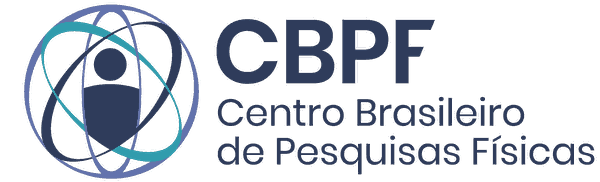

In [1]:
from pathlib import Path
import numpy as np
from easyspec.cleaning import cleaning
from easyspec.photometry import photometry

data = Path("eso_open_cluster_data")
out = Path("photometry_output")
out.mkdir(exist_ok=True)           #Creating the output directory

## 1. Reduction with `cleaning`

Three things are specific to the WFI, and all come from the header (`fits.getheader()` of any raw frame):

- **Trim**: each chip has 2142 x 4128 pixels. `ESO DET OUT2 PRSCX = 48` and `OVSCX = 48` are the
  prescan and overscan columns (on the left and on the right), and `OVSCY = 30` the overscan rows (at the bottom).
- **Gain**: `ESO DET OUT2 CONAD = 2.26` electrons per ADU (`gain_correct()` reads it from the header).
- **Read noise**: not in the header. We measure it from two bias frames: their difference contains only read noise, √2 times the noise
  of one frame.

In [2]:
bias_files = sorted((data/"bias").glob("*.fits"))
gain = 2.26
read_noise = 4.95
print(f"gain = {gain} e-/ADU, read noise = {read_noise:.2f} e-")

gain = 2.26 e-/ADU, read noise = 4.95 e-


One `cleaning` session per filter reduces the cluster and all the standard fields together (see the [image cleaning tutorial](https://github.com/ranieremenezes/easyspec/blob/main/tutorial/Image_cleaning_easyspec.ipynb) for details). The flats
are normalized with `method="imaging"` (it keeps all the structure of the response: vignetting, dust donuts), and every frame is saved
individually: each standard frame has its own airmass. The cluster and the standards are told apart later by their `OBJECT` keyword.

In [3]:
def reduce_filter(wfi_filter, plot=False):
    c = cleaning()

    # Folders of this filter
    bias_folder = data/"bias"
    flat_folder = data/f"flats_{wfi_filter}"
    cluster_folder = data/f"NGC_4755_{wfi_filter}"
    standard_folder = data/f"SA98_{wfi_filter}"

    # Read the raw frames
    raw = c.data_paths(bias=str(bias_folder), flats=str(flat_folder), standard_star=str(standard_folder),
                       targets=str(cluster_folder))

    # Remove the prescan and overscan
    trimmed = c.trim(raw, x1=200, x2=1800, y1=30, y2=2200)

    # Bias
    master_bias = c.master("bias", trimmed, plot=False)
    debiased = c.debias(trimmed, master_bias)

    # Flat field
    master_flat = c.master("flat", debiased, plot=False)
    norm_flat = c.norm_master_flat(master_flat, method="imaging", plots=False)
    flattened = c.flatten(debiased, norm_flat)

    # ADU -> electrons, cosmic rays, and the variance of every pixel
    electrons = c.gain_correct(flattened, gain=gain, verbose=False)
    cleaned = c.remove_cosmic_rays(electrons, readnoise=read_noise, verbose=False)
    variance, mask = c.compute_variance(cleaned, readnoise=read_noise, verbose=False)

    # Align the frames of each object onto its first frame (the variance and the mask follow the images). crop=False keeps the full
    # field: where a shifted frame has no data, its pixels are NaN (ignored by the photometry)
    aligned, aligned_variance, aligned_mask = c.align(cleaned, Type="all", crop=False, fill_value=np.nan,
                                                      variance=variance, mask=mask)

    # Combine the frames of each object into one image (mean: keeps the flux of the stars; exposure time and airmass = means)
    c.master("standard_star", aligned, method="mean", exposure_header_entry="EXPTIME", airmass_header_entry="ESO TEL AIRM START",
             variance=aligned_variance, mask=aligned_mask, plot=False)
    c.master("target", aligned, method="mean", exposure_header_entry="EXPTIME", airmass_header_entry="ESO TEL AIRM START",
             variance=aligned_variance, mask=aligned_mask, plot=plot)

    # master() writes the combined images in the working directory: move them to the output folders
    (out/f"standards_{wfi_filter}").mkdir(exist_ok=True)
    (out/f"NGC4755_{wfi_filter}").mkdir(exist_ok=True)
    Path("master_standard_star.fits").replace(out/f"standards_{wfi_filter}"/"master_standard_star.fits")
    Path(f"master_target_NGC_4755_{wfi_filter}.fits").replace(out/f"NGC4755_{wfi_filter}"/f"master_target_NGC_4755_{wfi_filter}.fits")

Normalized master flat: 2170/2170 illuminated rows; median = 0.9981; robust scatter = 0.0084; 29 pixels set to 1 (low signal).
18 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.24%, from 0.24% to 0.25% depending on the column.
Group 'NGC_4755_B_99' - reference image: WFI.2000-02-26T08:46:13.562.fits
Group 'SA98_B_99' - reference image: WFI.2000-02-26T00:43:37.760.fits
  WFI.2000-02-26T00:46:37.599.fits: method = stars, rotation = +0.003 deg, center shift (dx, dy) = (+0.84, -0.25) px, matched stars = 58, rms = 0.362 px


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master standard_star have different exposure times (9.918 to 14.918). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


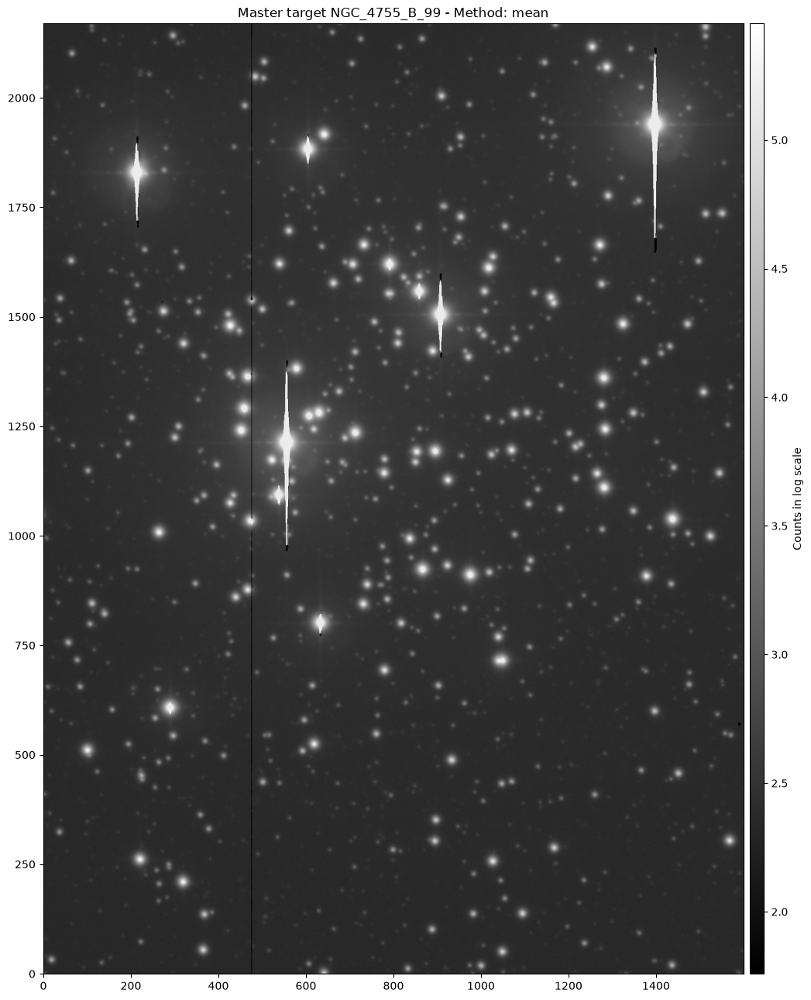

Normalized master flat: 2170/2170 illuminated rows; median = 0.9977; robust scatter = 0.0082; 30 pixels set to 1 (low signal).
19 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.25%, from 0.25% to 0.26% depending on the column.
Group 'NGC_4755_V_89' - reference image: WFI.2000-02-26T08:33:32.880.fits
Group 'SA98_V_89' - reference image: WFI.2000-02-26T00:50:22.716.fits
  WFI.2000-02-26T00:51:38.721.fits: method = stars, rotation = -0.003 deg, center shift (dx, dy) = (+128.97, -120.27) px, matched stars = 50, rms = 0.339 px


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master standard_star have different exposure times (9.991 to 19.991). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


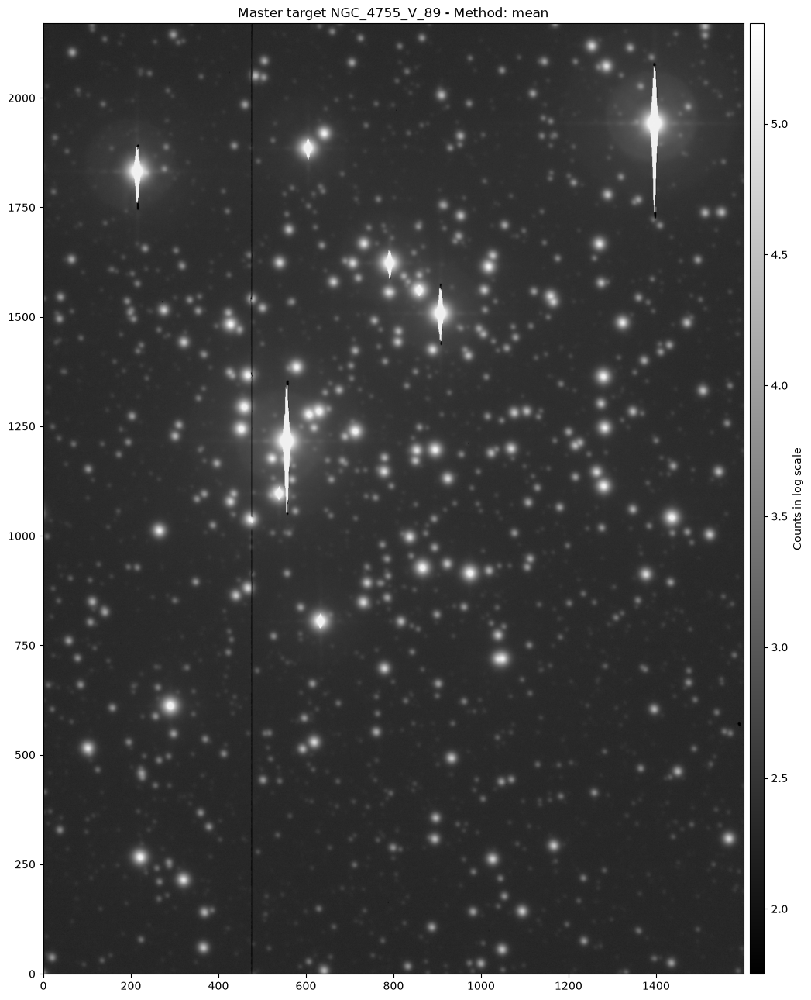

Normalized master flat: 2170/2170 illuminated rows; median = 1.0000; robust scatter = 0.0195; 32 pixels set to 1 (low signal).
24 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.42%, from 0.40% to 0.52% depending on the column.
Group 'NGC_4755_Ic_lwp' - reference image: WFI.2000-02-26T08:14:17.693.fits
Group 'SA98_Ic_lwp' - reference image: WFI.2000-02-26T00:53:40.544.fits
  WFI.2000-02-26T00:54:51.039.fits: method = stars, rotation = -0.001 deg, center shift (dx, dy) = (+134.26, -120.78) px, matched stars = 50, rms = 0.402 px


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master standard_star have different exposure times (9.991 to 19.991). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


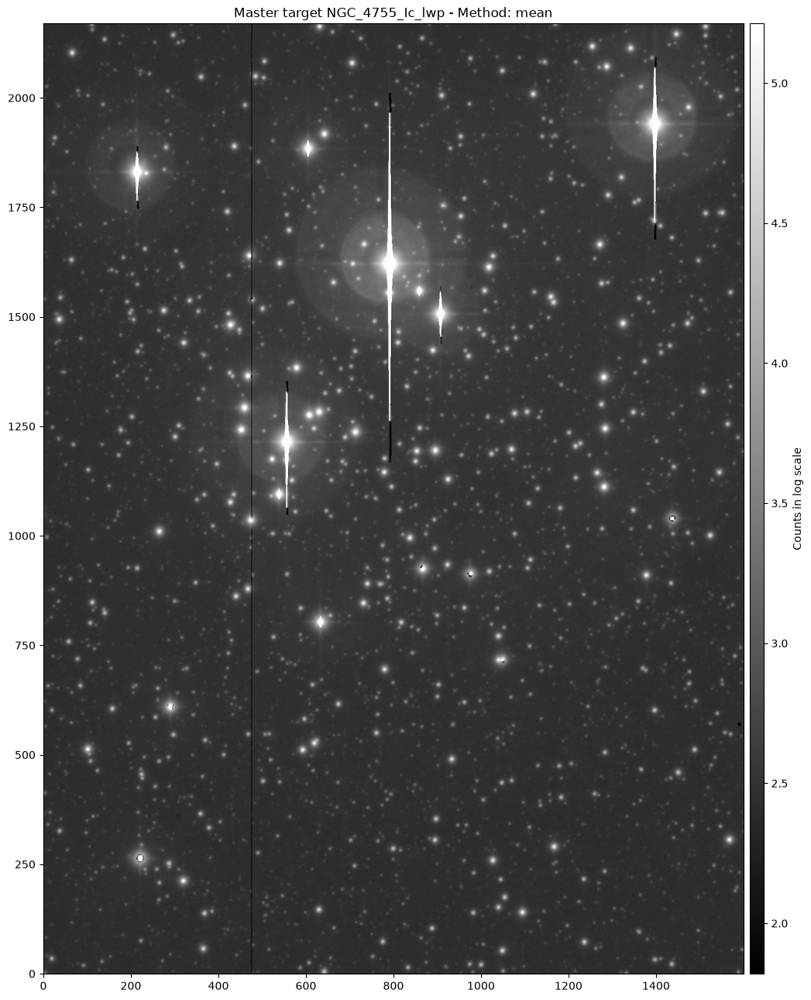

In [4]:
for wfi_filter in ("B_99", "V_89", "Ic_lwp"):
    reduce_filter(wfi_filter, plot=True)

## 2. A colored image of the cluster (optional)

The three reduced images of the cluster can be combined into a colored image with `generate_colored_image()`. Each image gets a color
(here blue for B, green for V and red for I), and the function does everything else:

- **aligns** the images: frames taken in different filters are shifted (and slightly rotated) by a few pixels, measured with the stars
  that the images have in common;
- **cuts the edges** where not all bands have data after the alignment;
- puts the bands on a **common flux scale**: each band is divided by its exposure time, and all bands share the same white point, so the
  colors show the real ratios of the count rates;
- **stretches** the result with a log scale, each color channel separately, as the RGB frames of DS9.

`plot_diagnostic=True` shows the aligned image before the cut, with the box that is kept; `plot_result=True` (default) shows the final
image. This function makes pictures: they must not be used for photometry.

Exposure times: NGC4755_B_99/master_target_NGC_4755_B_99.fits = 29.917 s, NGC4755_V_89/master_target_NGC_4755_V_89.fits = 29.917 s, NGC4755_Ic_lwp/master_target_NGC_4755_Ic_lwp.fits = 29.917 s
Group 'colored image' - reference image: master_target_NGC_4755_B_99.fits
  master_target_NGC_4755_V_89.fits: method = stars, rotation = +0.339 deg, center shift (dx, dy) = (+0.63, -0.11) px, matched stars = 16, rms = 1.321 px
  master_target_NGC_4755_Ic_lwp.fits: method = stars, rotation = -0.057 deg, center shift (dx, dy) = (-0.34, -1.96) px, matched stars = 12, rms = 0.837 px
Region with data in all 3 bands: x = 7-1594, y = 6-2165 (1587 x 2159 pixels)


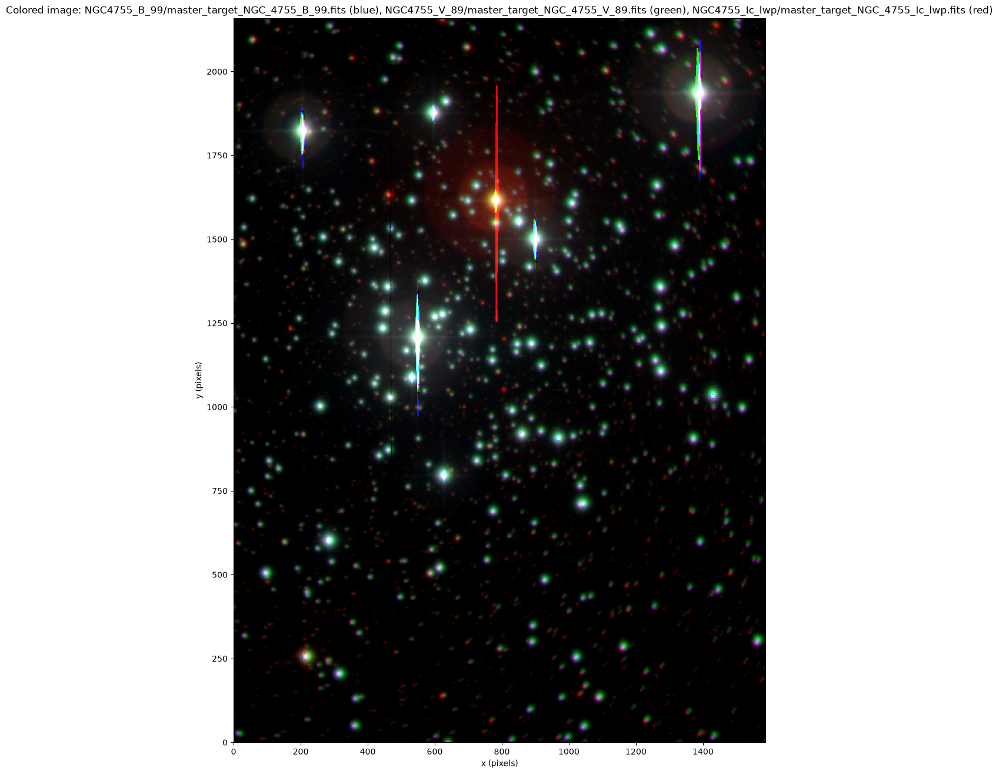

In [5]:
c = cleaning()

cluster_images = [out/"NGC4755_B_99"/"master_target_NGC_4755_B_99.fits",
                  out/"NGC4755_V_89"/"master_target_NGC_4755_V_89.fits",
                  out/"NGC4755_Ic_lwp"/"master_target_NGC_4755_Ic_lwp.fits"]
colors = ["blue", "green", "red"]

colored = c.generate_colored_image(cluster_images, colors, plot_diagnostic=False, plot_result=True)

The brightest stars are saturated in 30 s, and their charge overflows along the columns of the CCD: the vertical lines. Since this
image is only a picture, we can remove them with `remove_saturated_pixels=True`: the core of each saturated star is kept, and its trail
is replaced by the pixels on both sides of it.

Exposure times: NGC4755_B_99/master_target_NGC_4755_B_99.fits = 29.917 s, NGC4755_V_89/master_target_NGC_4755_V_89.fits = 29.917 s, NGC4755_Ic_lwp/master_target_NGC_4755_Ic_lwp.fits = 29.917 s
NGC4755_B_99/master_target_NGC_4755_B_99.fits: saturation level 139900; 24584 pixels of saturation trails replaced
NGC4755_V_89/master_target_NGC_4755_V_89.fits: saturation level 139665; 18996 pixels of saturation trails replaced
NGC4755_Ic_lwp/master_target_NGC_4755_Ic_lwp.fits: saturation level 141737; 29600 pixels of saturation trails replaced
Group 'colored image' - reference image: master_target_NGC_4755_B_99.fits
  master_target_NGC_4755_V_89.fits: method = stars, rotation = +0.011 deg, center shift (dx, dy) = (-0.02, -3.26) px, matched stars = 40, rms = 1.092 px
  master_target_NGC_4755_Ic_lwp.fits: method = stars, rotation = -0.007 deg, center shift (dx, dy) = (-0.22, -1.87) px, matched stars = 39, rms = 0.651 px
Region with data in all 3 bands: x = 1-1599, y = 0-2166 (1598 x 2166 pixels)

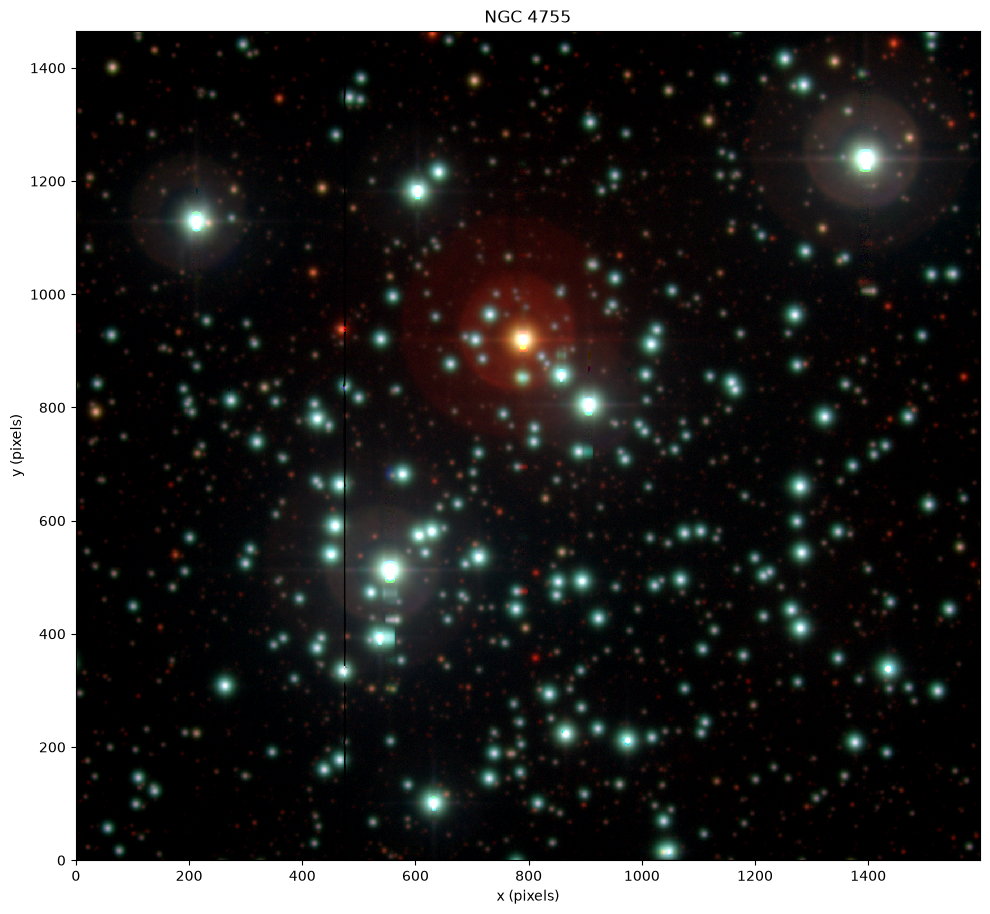

Colored image saved in photometry_output/jewel_box.png


In [6]:
colored = c.generate_colored_image(cluster_images, colors, remove_saturated_pixels=True, 
                                   output_file=out/"jewel_box.png",region=(0,1600,700,2200),title="NGC 4755")

### Making it look the way you like

The alignment and the removal of the trails are done only once. If we pass the result (`colored`) back to `generate_colored_image()`
instead of the file names, only the fast steps are redone, so we can try as many variations as we want. All the options can be combined:

| Option | What it does |
|---|---|
| `colors` | any matplotlib color, one per band: names (`"royalblue"`, `"gold"`), hex (`"#ff8800"`) or (r, g, b) tuples |
| `band_scaling` | `"exposure"` (default): common flux scale, real colors; `"separate"`: each band normalized on its own (stronger colors) |
| `zero_points` | zero point of each band: the bands become fluxes relative to Vega (an A0 star looks white) |
| `band_weights` | strength of each band, e.g. `[1.1, 1, 0.9]`: the main control of the color balance |
| `white_percentile` | percentile that becomes white (default 99.99); lower = brighter image, more saturated stars |
| `black_level` | black point in units of the sky noise (one value or one per band); > 0 hides the sky noise, < 0 makes the sky grey |
| `smoothing_sigma` | Gaussian smoothing in pixels (one value or one per band), to reduce noise |
| `stretch`, `stretch_strength` | `"log"` (default, strength 1000 as DS9), `"asinh"` or `"linear"`; a stronger stretch shows fainter stars |
| `color_mode` | `"channels"` (default, as DS9: white cores, colored wings) or `"preserve"` (colors kept up to the center of the stars) |
| `gamma` | < 1 brightens the faint parts, > 1 darkens them |
| `color_saturation` | 0 = grey scale, 1 = unchanged, > 1 = more vivid colors |
| `contrast`, `brightness` | contrast around mid grey, and overall brightness |
| `region` | `(x1, x2, y1, y2)`: zoom on a part of the image |
| `flip_x`, `flip_y` | mirror the image |
| `title`, `figure_size`, `show_axes` | appearance of the plot |
| `output_file`, `file_format` | save as png, or as fits (a cube with the planes R, G, B) |

**Real colors.** With `band_scaling="exposure"` the colors show count rates, which still include the sensitivity of the telescope and
detector in each filter. With the zero points of each band (`fit_standard_star_solution()`, Section 3 of this tutorial) the bands become
fluxes relative to Vega, and the colors are those of the stars: an A0 star is white.

**Removing the stars.** For a galaxy or a nebula behind a field of foreground stars, `remove_stars=True` fits every star with the PSF
photometry of the `photometry` module and subtracts it, leaving only the diffuse light (it takes a few minutes per image in crowded
fields). In an open cluster there is almost nothing behind the stars, so we do not use it here; for your own images:

    colored = c.generate_colored_image(images, colors, remove_stars=True)

## 3. Photometric calibration with standard stars

An instrumental magnitude, $m_\mathrm{inst} = -2.5\log_{10}(\text{electrons}/\text{s})$, depends on the telescope, the filter, the detector and
the atmosphere. The standard stars (stars with known magnitudes) tell us how to transform it into a standard magnitude $M$:

$$M = m_\mathrm{inst} + ZP - k\,X - c\,(\text{color})$$

- where $color = B-V$ or $color = V-I$, or something similar. 
- $ZP$, the **zero point**: the magnitude of a star that gives 1 electron per second above the atmosphere;
- $k$, the **extinction coefficient**: how much light the atmosphere absorbs per unit of airmass $X$ (larger in B than in I). This is why
  standard fields are observed at different airmasses during the night;
- $c$, the **color term**: the filters and the detector do not reproduce the standard system exactly, so a blue and a red star of the
  same standard magnitude give slightly different instrumental magnitudes.

The WFI keywords are given to `load_images()`: the filter is in `ESO INS FILT NAME` (renamed to B, V, I with `band_names`), the airmass
in `ESO TEL AIRM START`, the gain in `ESO DET OUT2 CONAD`; there is no saturation keyword, so the saturation of the 16-bit converter
(65535 ADU) is given directly.

In [7]:
phot = photometry()

# Header keywords of the WFI
filter_keyword = "ESO INS FILT NAME"
airmass_keyword = "ESO TEL AIRM START"
gain_keyword = "ESO DET OUT2 CONAD"
band_names = {"B/99": "B", "V/89": "V", "Ic/lwp": "I"}     # WFI filter names -> short names used in the tables
saturation_level = 65535                                     # ADU: the WFI headers have no saturation keyword

# The standard field SA98 (one combined image per filter)
standard_folders = [out/"standards_B_99", out/"standards_V_89", out/"standards_Ic_lwp"]
standards = phot.load_images(standard_folders, band_header_entry=filter_keyword, airmass_header_entry=airmass_keyword,
                             gain_header_entry=gain_keyword, band_names=band_names, saturation_level=saturation_level)

# The cluster (one combined image per filter)
cluster_folders = [out/"NGC4755_B_99", out/"NGC4755_V_89", out/"NGC4755_Ic_lwp"]
cluster = phot.load_images(cluster_folders, band_header_entry=filter_keyword, airmass_header_entry=airmass_keyword,
                           gain_header_entry=gain_keyword, band_names=band_names, saturation_level=saturation_level)

master_standard_star.fits: band B, 12.418 s, airmass 1.1509999999999998, 1600x2170 px, WCS: no
master_standard_star.fits: band V, 14.991 s, airmass 1.1475, 1600x2170 px, WCS: no
master_standard_star.fits: band I, 14.991 s, airmass 1.1455, 1600x2170 px, WCS: no
master_target_NGC_4755_B_99.fits: band B, 29.917 s, airmass 1.218, 1600x2170 px, WCS: no
master_target_NGC_4755_V_89.fits: band V, 29.917 s, airmass 1.205, 1600x2170 px, WCS: no
master_target_NGC_4755_Ic_lwp.fits: band I, 29.917 s, airmass 1.19, 1600x2170 px, WCS: no


First, the aperture photometry of all the standard-star frames. Then `fit_standard_star_solution()` needs to know which of the measured
stars are the standards:

- **with a WCS** (astrometric solution) in the header, **easyspec** projects the coordinates of the standards of a catalogue on the image.
  **easyspec** comes with the UBVRI catalogues of Landolt (`catalogue="landolt"`) and the faint UBVRI standards of Clem & Landolt in the same
  fields (`catalogue="clem_landolt"`, useful with large telescopes, where the Landolt stars saturate); `phot.available_standard_star_catalogues()`
  lists them, and `phot.standard_star_catalogue("landolt", field="SA98")` shows the stars of one field. Any csv file with name, ra, dec and
  magnitudes can also be used;
- **without a WCS**, as here (the WFI headers of 2000 only have the pointing of the telescope), we identify the standards ourselves:
  we compare one image (here the combined V image) with the finding chart of the field (Landolt 1992, 2009), and write down the position (x, y) of each standard and
  its magnitudes. The positions can be read in DS9 (subtract 1: DS9 counts pixels from 1, easyspec from 0). Instead of the magnitudes,
  we could give the names of the stars (column `name`, e.g. "98 650") and let easyspec take the magnitudes from the catalogue.

The positions are given once, in one image: the images of the other filters, which are shifted by a few pixels, are matched to it by
the positions of their stars.

In [8]:
# Except for the variable "standards", all other variables below are set at their default values
# i.e., running standard_photometry = phot.aperture_photometry(standards) would work exactly the same
B_std, V_std, I_std = phot.aperture_photometry(standards,aperture_radius=1.2, sky_annulus=(4.5, 6.5),
                                               correction_radius=4.0, apply_aperture_correction=True,
                                               correct_background_noise=True, positions=None,
                                               detection_threshold=5.0, fwhm="auto", background_box_size=64,
                                               verbose=True)

master_standard_star.fits: FWHM = 8.01 px, scatter 0.09 px from 40 stars; sky = 19.0 e-, RMS = 5.47 e-; 294 sources above 5.0 sigma
master_standard_star.fits: 294 stars (221 unflagged); aperture 9.6 px, annulus 36.0-52.1 px; aperture correction -0.137 mag from 19 stars (scatter 0.8%); background noise factor 1.69


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:391: UserWarning: master_standard_star.fits: the background fluctuates 1.7x more than the pixel variance predicts (unresolved stars or strongly correlated noise); the errors were scaled accordingly. In crowded fields aperture photometry is biased by blends: check the 'crowded' flag (16) and prefer psf_photometry().
  warnings.warn(f"{image.name}: the background fluctuates {noise_factor:.1f}x more than the pixel variance predicts (unresolved "


master_standard_star.fits: FWHM = 8.24 px, scatter 0.09 px from 38 stars; sky = 29.6 e-, RMS = 7.34 e-; 256 sources above 5.0 sigma
master_standard_star.fits: 256 stars (175 unflagged); aperture 9.9 px, annulus 37.1-53.5 px; aperture correction -0.131 mag from 20 stars (scatter 1.3%); background noise factor 1.54


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:391: UserWarning: master_standard_star.fits: the background fluctuates 1.5x more than the pixel variance predicts (unresolved stars or strongly correlated noise); the errors were scaled accordingly. In crowded fields aperture photometry is biased by blends: check the 'crowded' flag (16) and prefer psf_photometry().
  warnings.warn(f"{image.name}: the background fluctuates {noise_factor:.1f}x more than the pixel variance predicts (unresolved "


master_standard_star.fits: FWHM = 7.82 px, scatter 0.10 px from 38 stars; sky = 176.4 e-, RMS = 11.03 e-; 376 sources above 5.0 sigma
master_standard_star.fits: 376 stars (268 unflagged); aperture 9.4 px, annulus 35.2-50.8 px; aperture correction -0.151 mag from 15 stars (scatter 1.6%); background noise factor 3.22


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:391: UserWarning: master_standard_star.fits: the background fluctuates 3.2x more than the pixel variance predicts (unresolved stars or strongly correlated noise); the errors were scaled accordingly. In crowded fields aperture photometry is biased by blends: check the 'crowded' flag (16) and prefer psf_photometry().
  warnings.warn(f"{image.name}: the background fluctuates {noise_factor:.1f}x more than the pixel variance predicts (unresolved "


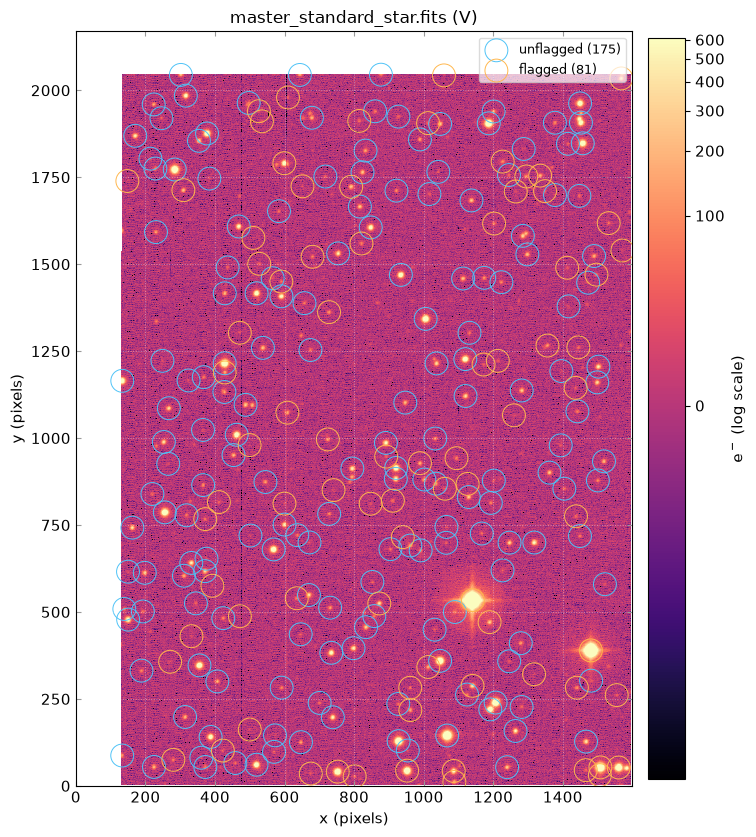

<Axes: title={'center': 'master_standard_star.fits (V)'}, xlabel='x (pixels)', ylabel='y (pixels)'>

In [9]:
phot.plot_image(standards[1], photometry_table=V_std)

Now we identify the standards. Comparing the combined V image with the finding chart of SA98 (Landolt 2009), we found nine Landolt
standards in our field. For each one we write down its position (x, y) on this image and its standard magnitudes: V and the colors
B − V and V − I (easyspec derives B and I from them). Then we circle them on the image to check that each position falls on the right
star.

Some of these stars lie close to the edges of the image (e.g. the ones at y ≈ 40): their sky annulus falls partly outside the image, so
they are flagged and will not enter the fit. That is fine: the other standards are enough.

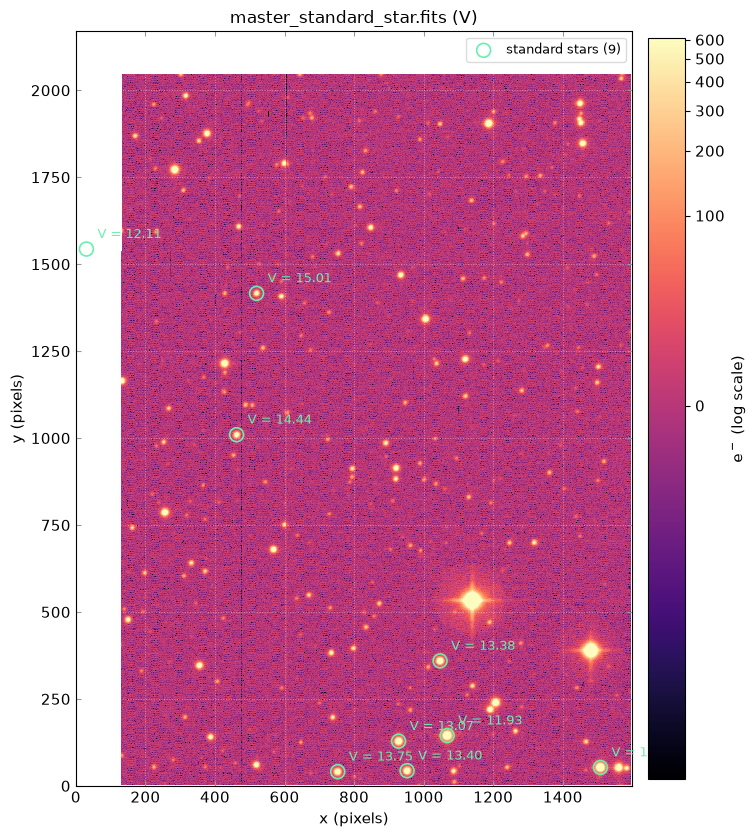

<Axes: title={'center': 'master_standard_star.fits (V)'}, xlabel='x (pixels)', ylabel='y (pixels)'>

In [10]:
# Landolt standards of SA98 on the combined V image: position (pixels) and standard magnitudes
reference_frame = "standards_V_89/master_standard_star.fits"
sa98_standards = [{"x": 1067.5, "y":  144.6, "V": 11.930, "B-V": 1.357, "V-I": 1.381},
                  {"x":   30.3, "y": 1543.5, "V": 12.113, "B-V": 0.314, "V-I": 0.388},
                  {"x": 1508.2, "y":   53.0, "V": 12.271, "B-V": 0.157, "V-I": 0.166},
                  {"x":  927.9, "y":  128.5, "V": 13.068, "B-V": 1.146, "V-I": 1.352},
                  {"x": 1047.2, "y":  359.4, "V": 13.385, "B-V": 0.968, "V-I": 1.071},
                  {"x":  952.4, "y":   43.6, "V": 13.398, "B-V": 1.909, "V-I": 2.085},
                  {"x":  753.0, "y":   40.8, "V": 13.749, "B-V": 0.632, "V-I": 0.717},
                  {"x":  462.1, "y": 1009.6, "V": 14.439, "B-V": 1.595, "V-I": 1.812},
                  {"x":  519.5, "y": 1416.2, "V": 15.010, "B-V": 0.835, "V-I": 1.102}]

# Check the identification: the standards circled on the reference frame
reference_image = standards[1]          # standards_V_89/master_standard_star.fits
phot.plot_image(reference_image, standard_stars=sa98_standards, marker_radius=5)

We make two solutions: one with the color B − V (for the B and V magnitudes) and one with V − I (for I). The extinction coefficient
can only be fitted if the standards were observed over a range of airmasses. Let's check:

In [11]:
for image in standards:
    print(f"{image.extra['path']}: band {image.band}, airmass {image.airmass:.3f}")

photometry_output/standards_B_99/master_standard_star.fits: band B, airmass 1.151
photometry_output/standards_V_89/master_standard_star.fits: band V, airmass 1.147
photometry_output/standards_Ic_lwp/master_standard_star.fits: band I, airmass 1.145


All the images of SA98 were taken at airmass 1.145-1.152: the extinction cannot be measured, so we fix it to typical values for La Silla.

**Note: with a WCS.** If the images had an astrometric solution in their headers, we would not need to identify the standards by hand:
easyspec would take their coordinates and magnitudes from one of its catalogues and find them on the images by itself. The fit would
simply be

    solution_BV = phot.fit_standard_star_solution(standard_photometry, catalogue="landolt", bands=("B", "V"), color_index=("B", "V"), fit_extinction=False, fixed_extinction=la_silla_extinction)

with no `standard_stars` and no `standard_stars_image` (`catalogue="clem_landolt"` would use the faint standards instead).

Standard stars given by hand: 9 measured on photometry_output/standards_V_89/master_standard_star.fits
   photometry_output/standards_B_99/master_standard_star.fits (B): 9 of 9 standards found (shift from photometry_output/standards_V_89/master_standard_star.fits: dx = +3.3, dy = -1.6 px)
   photometry_output/standards_V_89/master_standard_star.fits (V): 8 of 9 standards found
Band B: ZP = 25.3949 +/- 0.0857, k = 0.2200 +/- 0.0000 (fixed), c = -0.2784 +/- 0.0713 [color B-V]; rms = 0.0299 mag, reduced chi2 = 54.12, 5/5 measurements used
Band V: ZP = 24.9549 +/- 0.0176, k = 0.1300 +/- 0.0000 (fixed), c = +0.0435 +/- 0.0144 [color B-V]; rms = 0.0068 mag, reduced chi2 = 2.72, 5/5 measurements used


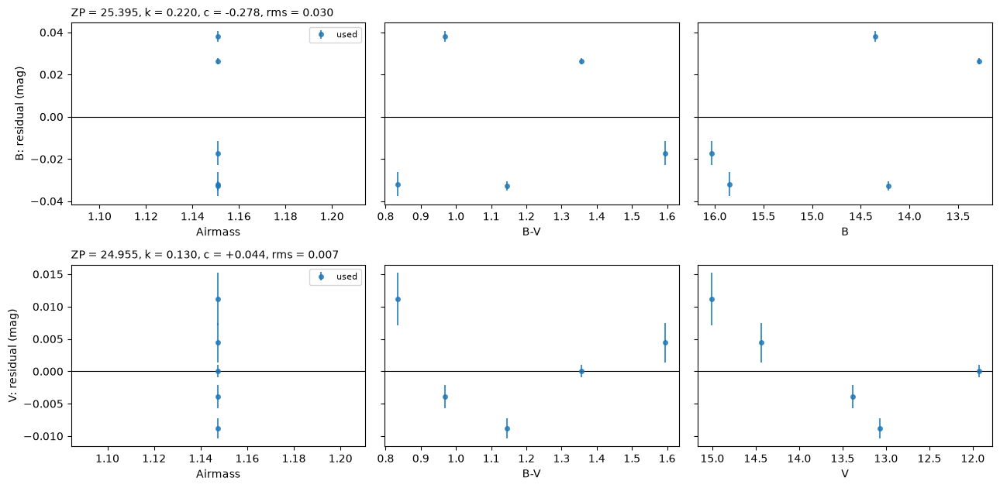

Standard stars given by hand: 9 measured on photometry_output/standards_V_89/master_standard_star.fits
   photometry_output/standards_V_89/master_standard_star.fits (V): 8 of 9 standards found
   photometry_output/standards_Ic_lwp/master_standard_star.fits (I): 8 of 9 standards found (shift from photometry_output/standards_V_89/master_standard_star.fits: dx = -8.9, dy = -2.7 px)
Band V: ZP = 24.9548 +/- 0.0258, k = 0.1300 +/- 0.0000 (fixed), c = +0.0384 +/- 0.0187 [color V-I]; rms = 0.0091 mag, reduced chi2 = 4.60, 5/5 measurements used
Band I: ZP = 23.8639 +/- 0.0263, k = 0.0600 +/- 0.0000 (fixed), c = -0.1956 +/- 0.0188 [color V-I]; rms = 0.0087 mag, reduced chi2 = 2.36, 5/5 measurements used


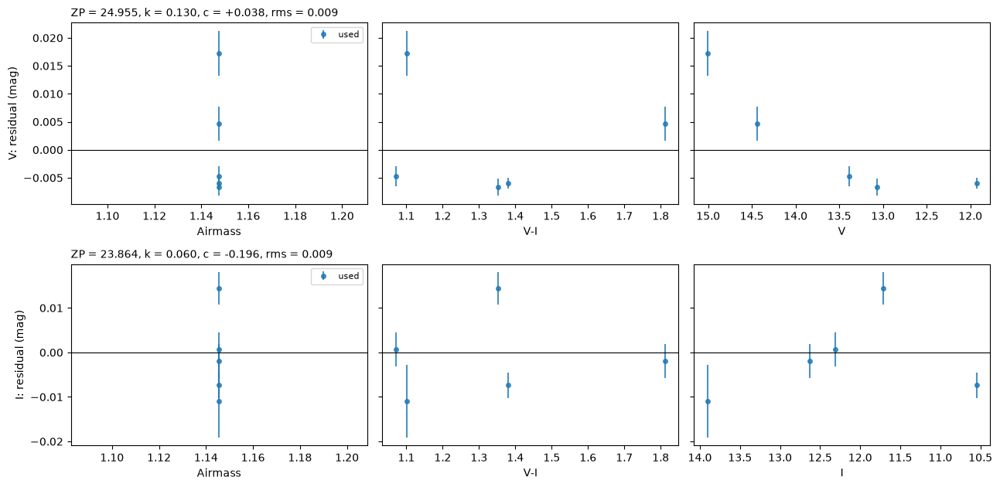

In [12]:
la_silla_extinction = {"B": 0.22, "V": 0.13, "I": 0.06}     # mag per airmass
standard_photometry = [B_std, V_std, I_std]

solution_BV = phot.fit_standard_star_solution(standard_photometry, standard_stars=sa98_standards, standard_stars_image=reference_frame,
                                              bands=("B", "V"), color_index=("B", "V"),
                                              fit_extinction=False, fixed_extinction=la_silla_extinction)

solution_VI = phot.fit_standard_star_solution(standard_photometry, standard_stars=sa98_standards, standard_stars_image=reference_frame,
                                              bands=("V", "I"), color_index=("V", "I"),
                                              fit_extinction=False, fixed_extinction=la_silla_extinction)

## 4. Aperture photometry of the cluster

The idea is simple: add up the electrons inside a circle around the star and subtract the sky that falls inside the same circle. The
details are what make it precise:

1. **Detection and FWHM** (`find_stars()`): a background map is computed (median in boxes, after masking the stars), the FWHM of the
   stars is measured with 2D Gaussian fits to bright isolated stars, and the stars are detected with DAOStarFinder.
2. **Local sky**: for each star, the sky is the sigma-clipped median of an annulus between 4.5 and 6.5 FWHM, excluding the pixels of
   other stars. A local sky follows gradients that a global background would miss.
3. **Aperture size**: a large aperture collects all the light but also a lot of sky noise; for faint stars the best signal-to-noise is
   reached with a radius of about 1 FWHM. We use 1.2 FWHM.
4. **Aperture correction**: a small aperture misses the wings of the star. The missing fraction is the same for all stars (they share
   the PSF), so it is measured on bright isolated stars (ratio between the flux in 4 FWHM and in 1.2 FWHM) and applied to all.
5. **Uncertainties**: the variance of every pixel comes from `cleaning.compute_variance()` (photon, read, bias and flat-field noise),
   plus the uncertainty of the sky level. The "background noise factor" compares them with the scatter of empty-sky apertures: in this
   rich field it is 2-4 (larger in I, where the faint red field stars are more numerous), because of the many faint stars below the
   detection limit, and the errors are increased accordingly.
6. **Flags** (`photometry.FLAG_BITS`): every star has a `flags` column, the sum of the bits of all the problems found (e.g. 5 = 1 + 4):
   - **1**: saturated: the peak of the star is above 85% of the saturation level (non-linear regime);
   - **2**: bad pixels in the aperture (non-finite values, or pixels where the flat field could not be applied);
   - **4**: cosmic-ray pixels in the aperture (replaced by `remove_cosmic_rays()`, so the flux there is only an estimate);
   - **8**: the aperture or the sky annulus is partly outside the image (stars near the edges);
   - **16**: crowded: another star closer than (aperture radius + 1.5 FWHM) and brighter than 1% of this star adds light to the
     aperture;
   - **32**: low signal-to-noise (S/N < 5);
   - **64**: PSF fit problem (only in `psf_photometry()`).

   Flagged stars are kept in the tables, but should not be trusted blindly. Here the brightest members of the cluster (κ Cru has V ≈ 6)
   are saturated even in 30 s.

master_target_NGC_4755_B_99.fits: FWHM = 7.03 px, scatter 0.02 px from 40 stars; sky = 267.9 e-, RMS = 20.92 e-; 1230 sources above 5.0 sigma
master_target_NGC_4755_B_99.fits: 1230 stars (994 unflagged); aperture 8.4 px, annulus 31.6-45.7 px; aperture correction -0.171 mag from 20 stars (scatter 2.7%); background noise factor 1.99


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:391: UserWarning: master_target_NGC_4755_B_99.fits: the background fluctuates 2.0x more than the pixel variance predicts (unresolved stars or strongly correlated noise); the errors were scaled accordingly. In crowded fields aperture photometry is biased by blends: check the 'crowded' flag (16) and prefer psf_photometry().
  warnings.warn(f"{image.name}: the background fluctuates {noise_factor:.1f}x more than the pixel variance predicts (unresolved "


master_target_NGC_4755_V_89.fits: FWHM = 9.18 px, scatter 0.08 px from 40 stars; sky = 245.2 e-, RMS = 19.87 e-; 1056 sources above 5.0 sigma
master_target_NGC_4755_V_89.fits: 1056 stars (808 unflagged); aperture 11.0 px, annulus 41.3-59.7 px; aperture correction -0.163 mag from 11 stars (scatter 2.5%); background noise factor 2.86


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:391: UserWarning: master_target_NGC_4755_V_89.fits: the background fluctuates 2.9x more than the pixel variance predicts (unresolved stars or strongly correlated noise); the errors were scaled accordingly. In crowded fields aperture photometry is biased by blends: check the 'crowded' flag (16) and prefer psf_photometry().
  warnings.warn(f"{image.name}: the background fluctuates {noise_factor:.1f}x more than the pixel variance predicts (unresolved "


master_target_NGC_4755_Ic_lwp.fits: FWHM = 5.08 px, scatter 0.04 px from 40 stars; sky = 309.9 e-, RMS = 23.12 e-; 3215 sources above 5.0 sigma
master_target_NGC_4755_Ic_lwp.fits: 3215 stars (2283 unflagged); aperture 6.1 px, annulus 22.9-33.0 px; aperture correction -0.216 mag from 20 stars (scatter 2.4%); background noise factor 4.05


/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:391: UserWarning: master_target_NGC_4755_Ic_lwp.fits: the background fluctuates 4.1x more than the pixel variance predicts (unresolved stars or strongly correlated noise); the errors were scaled accordingly. In crowded fields aperture photometry is biased by blends: check the 'crowded' flag (16) and prefer psf_photometry().
  warnings.warn(f"{image.name}: the background fluctuates {noise_factor:.1f}x more than the pixel variance predicts (unresolved "


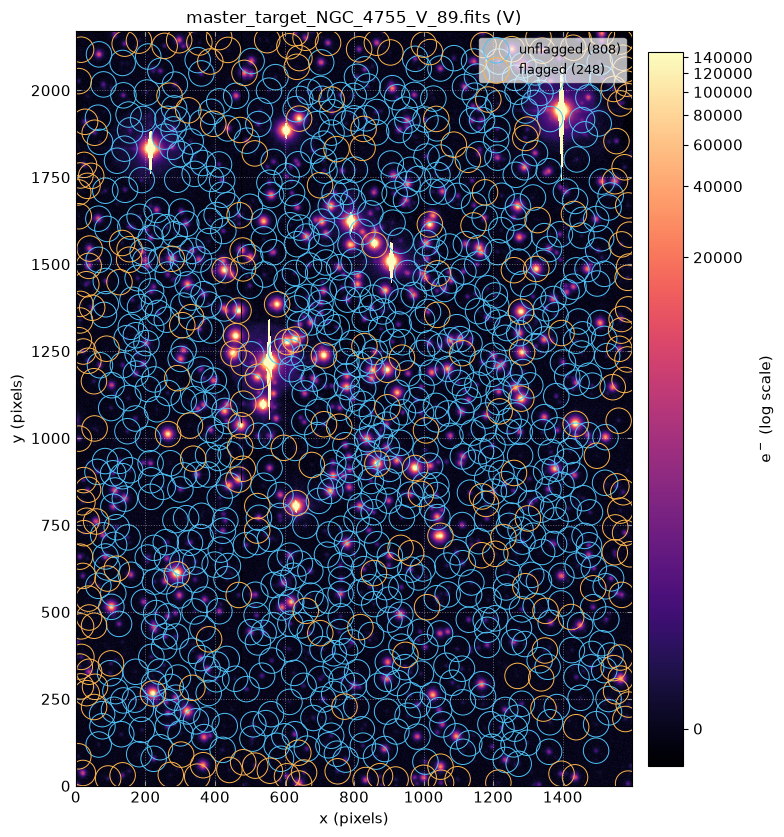

<Axes: title={'center': 'master_target_NGC_4755_V_89.fits (V)'}, xlabel='x (pixels)', ylabel='y (pixels)'>

In [13]:
# All the options are at their default values: phot.aperture_photometry(cluster) would give exactly the same result
B, V, I = phot.aperture_photometry(cluster,
                                   aperture_radius=1.2,             # radius of the photometry aperture, in FWHM
                                   sky_annulus=(4.5, 6.5),          # inner and outer radius of the sky annulus, in FWHM
                                   correction_radius=4.0,           # "total" aperture of the aperture correction, in FWHM
                                   apply_aperture_correction=True,
                                   correct_background_noise=True,   # scale the errors by the background noise factor
                                   positions=None,                  # or a list of (x, y) to measure only those positions
                                   detection_threshold=5.0,         # detection threshold, in sigmas of the background
                                   fwhm="auto",                     # measured on the image, or a value in pixels
                                   background_box_size=64)          # box size (pixels) of the background map
phot.plot_image(cluster[1], photometry_table=V)

## 5. Color-magnitude diagrams

`calibrate_magnitudes()` matches the stars of two filters (the images are not aligned to each other: the shift between them is found
automatically) and solves the two transformation equations together, giving the magnitudes and the color of every star.

The images were reduced from y = 0 to include the standard stars of SA98, which lie in the lower part of the chip. For the cluster we
keep only the stars above y = 500, around the center of the cluster.

master_target_NGC_4755_V_89.fits -> master_target_NGC_4755_B_99.fits: offset dx = +0.05, dy = -3.44 px; 923 stars matched
923 stars with B and V; calibration (systematic) uncertainty: B 0.027, V 0.011, B-V 0.031 mag


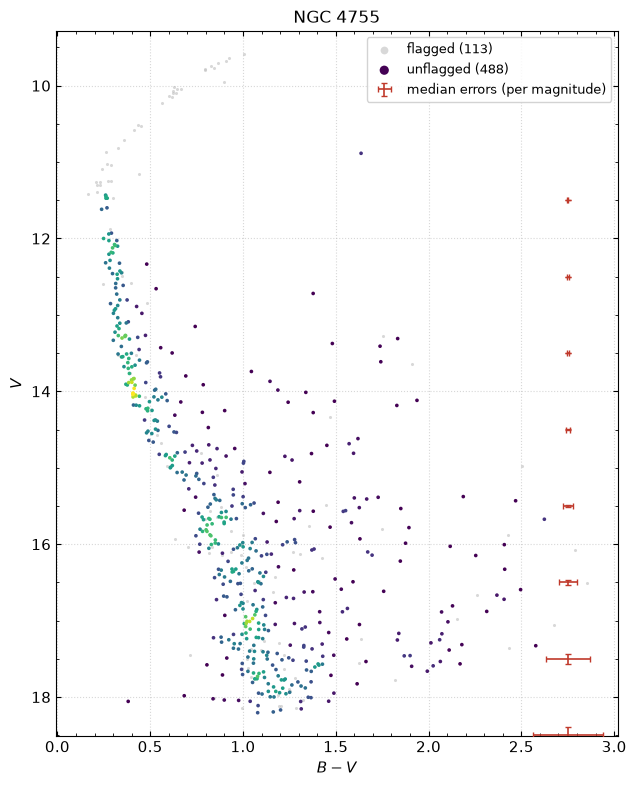

PosixPath('photometry_output/NGC4755_BV.csv')

In [14]:
cluster_BV = phot.calibrate_magnitudes([B, V], solution_BV)
cluster_BV = cluster_BV[cluster_BV["y"] > 500]          # only the region of the cluster
phot.plot_color_magnitude_diagram(cluster_BV, title="NGC 4755")
phot.save_table(cluster_BV, out/"NGC4755_BV.csv")

master_target_NGC_4755_Ic_lwp.fits -> master_target_NGC_4755_V_89.fits: offset dx = -0.02, dy = +1.47 px; 1032 stars matched
1032 stars with V and I; calibration (systematic) uncertainty: V 0.011, I 0.008, V-I 0.014 mag


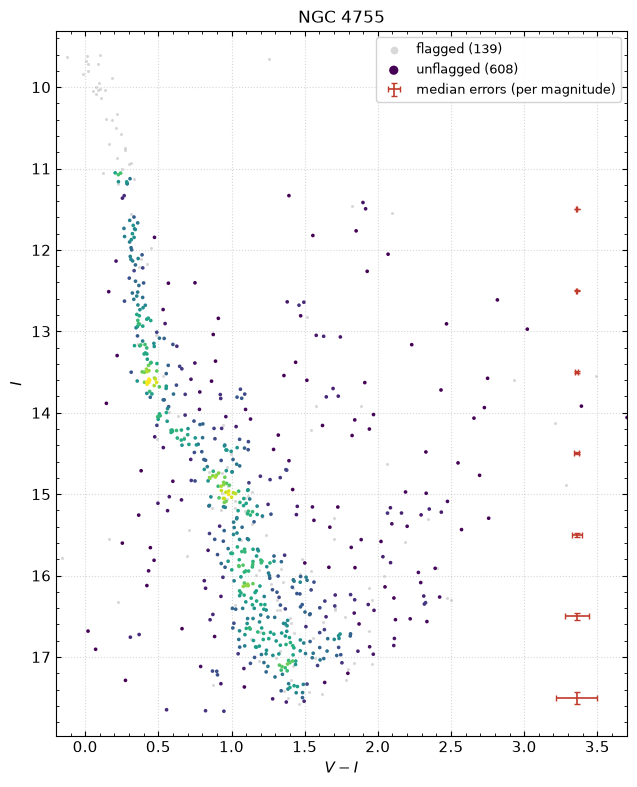

PosixPath('photometry_output/NGC4755_VI.csv')

In [15]:
cluster_VI = phot.calibrate_magnitudes([V, I], solution_VI)
cluster_VI = cluster_VI[cluster_VI["y"] > 500]          # only the region of the cluster
phot.plot_color_magnitude_diagram(cluster_VI, title="NGC 4755")
phot.save_table(cluster_VI, out/"NGC4755_VI.csv")

The cluster is the narrow, almost vertical sequence of blue stars at the top left: the upper main sequence of a young cluster, made of hot
B stars of nearly the same color, which becomes slightly redder towards fainter (cooler) stars. The broad cloud of redder and fainter stars
is the Milky Way field in the direction of the cluster (Crux is in the Galactic plane). The flagged stars (grey) at the top of the
sequence are saturated: their magnitudes and colors are wrong, and shorter exposures would be needed for them.

The intrinsic color of hot B stars is B − V ≈ −0.2 to −0.3: the difference with the observed color of the cluster sequence is the
reddening by interstellar dust, E(B − V). With it, the comparison with isochrones (argument `isochrone` of
`plot_color_magnitude_diagram()`) gives the distance and the age of the cluster.

The magnitude tables can be checked as shown below:

In [16]:
cluster_VI[0:10]

id,x,y,V,V_error,I,I_error,V-I,V-I_error,flags_V,flags_I,flags
int64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64
1,608.228790575329,1276.1423295465047,9.710313523556696,0.0007858323533449066,9.610653972679723,0.0017007349969714672,0.09965955087697351,0.0017597204886816477,17,1,17
2,460.76345548111897,1293.0679001890267,9.628223951430225,0.0007789136821210968,9.618756310431737,0.0019294133456613971,0.009467640998489376,0.0019642911520318268,1,1,1
3,290.53816264971994,608.2738874316487,9.501638998933174,0.000757362740483468,9.62918482891296,0.001851254484151134,-0.12754582997978686,0.0018874116862336084,1,5,5
4,789.5764916929396,1555.8323477913282,10.908182142832398,0.0012011799806450067,9.653812824415507,0.0017943582157319902,1.2543693184168916,0.0019891393793835094,0,1,1
5,630.3014422885612,1283.1205317344072,9.68227376568425,0.0008106213398504582,9.67710329041875,0.001800055555425624,0.005170475265500342,0.001856196981962759,17,1,17
7,867.0117013118027,926.1449258734687,9.803310942831892,0.0008227790787995845,9.717170747990126,0.0018101865914173273,0.08614019484176676,0.0018688912672502932,1,5,5
8,453.2045146967133,1242.8799222972546,9.739935444880496,0.0008118351492408167,9.719652407366036,0.0019923961464708125,0.02028303751445974,0.002030426265397226,1,1,1
9,713.3244001548986,1237.8468813468144,9.818520798325858,0.00084127716274008,9.799286256749705,0.0018666122357953534,0.019234541576154236,0.0019250308949064587,1,1,1
10,1437.0122520778027,1040.9131457274373,9.829062897251106,0.0008264348925607837,9.843852259560148,0.00230563672878211,-0.014789362309042228,0.002320807130218577,1,5,5


## 6. Calibrating with less data

With two filters, `calibrate_magnitudes()` solves the color of every star together with its magnitudes. But we can also calibrate a
single filter, e.g. if we had only the V images of the standards and of the cluster.

The solution itself still has a color term: it is fitted with the catalogue colors of the standards (their B − V from Landolt), so no
B image is needed.

Standard stars given by hand: 9 measured on photometry_output/standards_V_89/master_standard_star.fits
   photometry_output/standards_V_89/master_standard_star.fits (V): 8 of 9 standards found
Band V: ZP = 24.9549 +/- 0.0176, k = 0.1300 +/- 0.0000 (fixed), c = +0.0435 +/- 0.0144 [color B-V]; rms = 0.0068 mag, reduced chi2 = 2.72, 5/5 measurements used


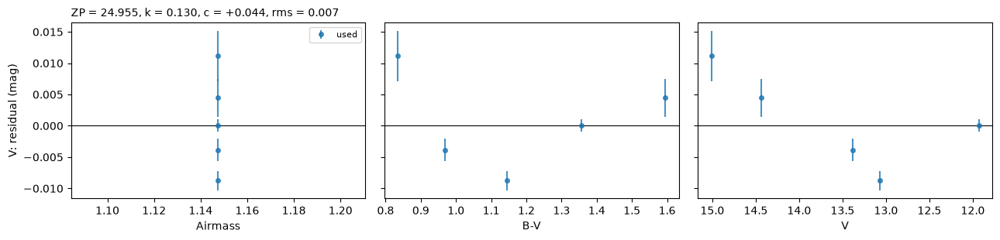

In [17]:
solution_V = phot.fit_standard_star_solution([V_std], standard_stars=sa98_standards, standard_stars_image=reference_frame,
                                             bands=("V",), color_index=("B", "V"),
                                             fit_extinction=False, fixed_extinction=la_silla_extinction)

For the cluster, however, the colors of the stars are unknown. `calibrate_magnitudes()` then uses color = 0, or the color we give
with `color_index_values` (one value for all stars, or one per star). The error is c × (true color − color used): small in V, where
c ≈ 0.05, larger in B and I.

In [18]:
cluster_V = phot.calibrate_magnitudes(V, solution_V)                               # color of all stars = 0
cluster_V_assumed = phot.calibrate_magnitudes(V, solution_V, color_index_values=0.25)  # color of the cluster sequence
cluster_V[:5]

/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/photometry.py:1264: UserWarning: Band V: no colors given; the color term (c = +0.044) is neglected.
  warnings.warn(f"Band {band}: no colors given; the color term (c = {coefficients['c']:+.3f}) is neglected.")


id,x,y,V,V_error,flags
int64,float64,float64,float64,float64,int64
1,290.53816264971994,608.2738874316487,9.496838349780019,0.0007784956380582462,1
2,633.334267125075,813.0133276332183,9.44409785995671,0.0008036828581251856,5
3,713.3244001548986,1237.8468813468144,9.81935460323296,0.0008653779476252117,1
4,1017.7687839546139,1614.3399979799262,10.248527048269656,0.0009916178011979426,1
5,641.9799445238109,1918.4423558189756,10.176399492935925,0.0009845816343146765,1


Compared with the two-filter magnitudes, color = 0 makes the cluster stars (B − V ≈ 0.25) 0.01 mag fainter and the red field stars
(B − V > 1) 0.06 mag fainter; with color_index_values=0.25 the cluster stars are right within 0.002 mag.


The color term c is the slope of M − m_inst + kX against the color of the standards. If the standards do not cover a range of colors
(or there are only one or two of them), this slope cannot be measured. But c depends on the filter, the detector and the telescope, not
on the night: it can be measured once, on a night with many standards of different colors, and then kept fixed on the other nights
(`fit_color_term=False, fixed_color_term={"V": 0.05}`). With `fit_color_term=False` alone, c is fixed to zero.

Standard stars given by hand: 9 measured on photometry_output/standards_V_89/master_standard_star.fits
   photometry_output/standards_V_89/master_standard_star.fits (V): 8 of 9 standards found
Band V: ZP = 24.9029 +/- 0.0066, k = 0.1300 +/- 0.0000 (fixed), c = +0.0000 +/- 0.0000 (fixed) [color B-V]; rms = 0.0142 mag, reduced chi2 = 8.28, 5/5 measurements used


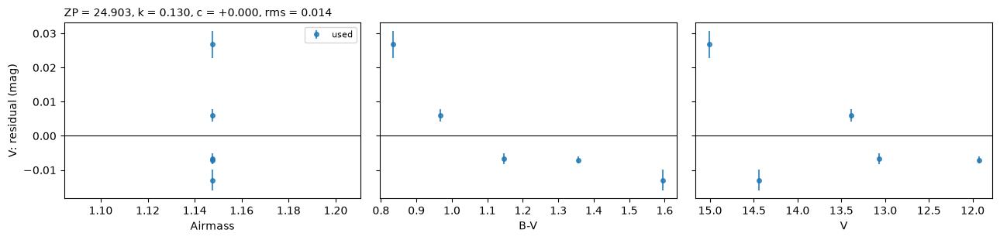

In [19]:
solution_V_no_color = phot.fit_standard_star_solution([V_std], standard_stars=sa98_standards, standard_stars_image=reference_frame,
                                                      bands=("V",), color_index=("B", "V"), fit_color_term=False,
                                                      fit_extinction=False, fixed_extinction=la_silla_extinction)
cluster_V_no_color = phot.calibrate_magnitudes(V, solution_V_no_color)

Without a color term, the zero point absorbs the color term of the standards: it is right for stars with their colors (here B − V ≈ 1,
like the field stars) and off for the others (here 0.05 mag for the blue cluster stars). The lesson: when the color term is ignored,
choose standards with colors similar to those of the targets.

If you know that the color term is, e.g., V = 0.05, you can do the following:

Standard stars given by hand: 9 measured on photometry_output/standards_V_89/master_standard_star.fits
   photometry_output/standards_V_89/master_standard_star.fits (V): 8 of 9 standards found
Band V: ZP = 24.9626 +/- 0.0034, k = 0.1300 +/- 0.0000 (fixed), c = +0.0500 +/- 0.0000 (fixed) [color B-V]; rms = 0.0069 mag, reduced chi2 = 2.18, 5/5 measurements used


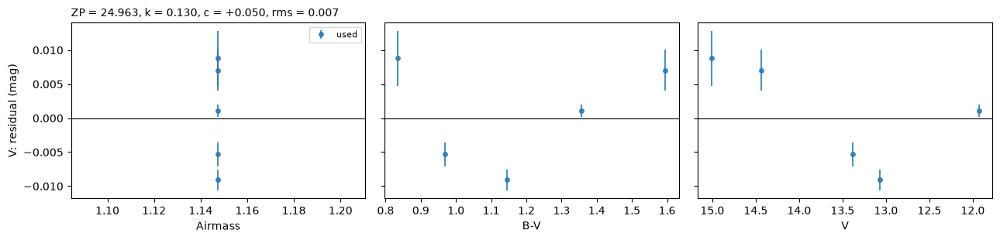

In [20]:
solution_V_known_c = phot.fit_standard_star_solution([V_std], standard_stars=sa98_standards, standard_stars_image=reference_frame,
                                                     bands=("V",), color_index=("B", "V"),
                                                     fit_color_term=False, fixed_color_term={"V": 0.05},
                                                     fit_extinction=False, fixed_extinction=la_silla_extinction)

In [21]:
cluster_V_no_color

id,x,y,V,V_error,flags
int64,float64,float64,float64,float64,int64
1,290.53816264971994,608.2738874316487,9.44486482593692,0.0007784956380582462,1
2,633.334267125075,813.0133276332183,9.39212433611361,0.0008036828581251856,5
3,713.3244001548986,1237.8468813468144,9.76738107938986,0.0008653779476252117,1
4,1017.7687839546139,1614.3399979799262,10.196553524426557,0.0009916178011979426,1
5,641.9799445238109,1918.4423558189756,10.124425969092826,0.0009845816343146765,1
6,467.70957640358324,1366.4730818759529,9.992551013643778,0.0009219311452166714,5
7,474.4341788102917,1036.5644793523873,10.026510770512512,0.0031129681072709706,5
8,895.5237910854635,1196.3290476408258,10.04643331469209,0.0009478896613316455,1
9,460.76345548111897,1293.0679001890267,9.576709310752086,0.0008005591116711143,1
